In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [3]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python is working!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nCSV files available:")
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))


DATA_DIR = "/kaggle/input/competitions/ieee-fraud-detection"

transaction_sample = pd.read_csv(
    f"{DATA_DIR}/train_transaction.csv",
    nrows=1000
)

identity_sample = pd.read_csv(
    f"{DATA_DIR}/train_identity.csv",
    nrows=1000
)

print("Transaction:", transaction_sample.shape)
print("Identity:", identity_sample.shape)

print("\nFraud counts:")
print(transaction_sample["isFraud"].value_counts())

Python is working!
Pandas version: 2.3.3
NumPy version: 2.1.3

CSV files available:
/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv
Transaction: (1000, 394)
Identity: (1000, 41)

Fraud counts:
isFraud
0    985
1     15
Name: count, dtype: int64


In [4]:

from pathlib import Path

DATA_DIR = Path("/kaggle/input")

for path in DATA_DIR.rglob("*.csv"):
    print(path)


/kaggle/input/competitions/ieee-fraud-detection/sample_submission.csv
/kaggle/input/competitions/ieee-fraud-detection/test_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/train_identity.csv
/kaggle/input/competitions/ieee-fraud-detection/test_transaction.csv
/kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

transaction_files = list(DATA_DIR.rglob("train_transaction.csv"))
identity_files = list(DATA_DIR.rglob("train_identity.csv"))

assert transaction_files, "train_transaction.csv was not found"
assert identity_files, "train_identity.csv was not found"

transaction_path = transaction_files[0]
identity_path = identity_files[0]

start = time.time()

transactions = pd.read_csv(transaction_path, nrows=5000)
identity = pd.read_csv(identity_path, nrows=5000)

print("Transaction sample shape:", transactions.shape)
print("Identity sample shape:", identity.shape)
print("Loading time:", round(time.time() - start, 2), "seconds")

display(transactions.head(5))


Transaction sample shape: (5000, 394)
Identity sample shape: (5000, 41)
Loading time: 0.31 seconds


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:

print("Fraud label counts:")
print(transactions["isFraud"].value_counts())

print("\nFraud label percentages:")
print(
    (transactions["isFraud"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing fraud labels:")
print(transactions["isFraud"].isna().sum())


Fraud label counts:
isFraud
0    4891
1     109
Name: count, dtype: int64

Fraud label percentages:
isFraud
0    97.82
1     2.18
Name: proportion, dtype: float64

Missing fraud labels:
0


In [7]:

print("TransactionDT summary:")
print(transactions["TransactionDT"].describe())

print("\nFirst 10 transaction times:")
print(transactions["TransactionDT"].head(10).to_list())

print(
    "\nAre the first 5,000 rows sorted by TransactionDT?",
    transactions["TransactionDT"].is_monotonic_increasing
)


TransactionDT summary:
count      5000.000000
mean     139599.938800
std       24886.671042
min       86400.000000
25%      129170.500000
50%      146625.500000
75%      158543.750000
max      171642.000000
Name: TransactionDT, dtype: float64

First 10 transaction times:
[86400, 86401, 86469, 86499, 86506, 86510, 86522, 86529, 86535, 86536]

Are the first 5,000 rows sorted by TransactionDT? True


# Dataset Audit — Initial Sample

## Purpose
Verify dataset access and understand the basic structure of the IEEE-CIS Fraud Detection dataset.

## Files
- Transaction file: confirmed
- Identity file: confirmed

## Initial sample
- Transaction sample rows: 5,000
- Transaction columns: 394
- Identity sample rows: 5,000
- Identity columns: 41
- Loading time: 0.34 seconds

## Fraud label
- Non-fraud transactions: 4,891
- Fraud transactions: 109
- Fraud percentage in this sample: 2.18%
- Missing fraud labels: 0

## Time variable
- TransactionDT minimum: 86,400
- TransactionDT maximum: 171,642
- Rows sorted by TransactionDT: yes

## Initial interpretation
The sample contains substantially more non-fraud transactions than fraudulent transactions. This is a class-imbalanced classification problem. TransactionDT increases across the first 5,000 rows, which supports investigating chronological evaluation.

## Limitations
These results describe only the first 5,000 transaction rows. The observed fraud rate is not necessarily representative of the complete dataset. The sorted sample does not establish that every row in the full dataset is sorted, nor does it prove concept drift.

## Next step
Audit the complete transaction dataset and examine its time coverage, missing values, and fraud distribution.

In [8]:

from pathlib import Path
import time
import pandas as pd
import numpy as np

# Find the training transaction file again
matches = list(
    Path("/kaggle/input").rglob("train_transaction.csv")
)

if not matches:
    raise FileNotFoundError(
        "Could not find train_transaction.csv. Check Kaggle's Input panel."
    )

transaction_path = matches[0]
print("Using file:", transaction_path)

# Load only the columns needed for this audit
audit_columns = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD"
]

start = time.time()

audit_df = pd.read_csv(
    transaction_path,
    usecols=audit_columns
)

print("\nFull transaction audit shape:", audit_df.shape)
print("Loading time:", round(time.time() - start, 2), "seconds")

print("\nMissing values:")
print(audit_df.isna().sum())

print("\nDuplicate TransactionIDs:")
print(audit_df["TransactionID"].duplicated().sum())

print("\nFraud counts:")
print(audit_df["isFraud"].value_counts())

print("\nFraud percentages:")
print(
    (audit_df["isFraud"].value_counts(normalize=True) * 100).round(3)
)

print("\nTransactionDT range:")
print("Minimum:", audit_df["TransactionDT"].min())
print("Maximum:", audit_df["TransactionDT"].max())

print(
    "\nEntire dataset sorted by TransactionDT:",
    audit_df["TransactionDT"].is_monotonic_increasing
)


Using file: /kaggle/input/competitions/ieee-fraud-detection/train_transaction.csv

Full transaction audit shape: (590540, 5)
Loading time: 9.74 seconds

Missing values:
TransactionID     0
isFraud           0
TransactionDT     0
TransactionAmt    0
ProductCD         0
dtype: int64

Duplicate TransactionIDs:
0

Fraud counts:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud percentages:
isFraud
0    96.501
1     3.499
Name: proportion, dtype: float64

TransactionDT range:
Minimum: 86400
Maximum: 15811131

Entire dataset sorted by TransactionDT: True


,transactions,fraud_cases,start_time,end_time,fraud_rate_percent
time_window,,,,,
Window 1,118108,2826,86400,2310138,2.393
Window 2,118108,4732,2310165,5592303,4.007
Window 3,118108,4430,5592304,8745772,3.751
Window 4,118108,4611,8745798,12192842,3.904
Window 5,118108,4064,12192900,15811131,3.441


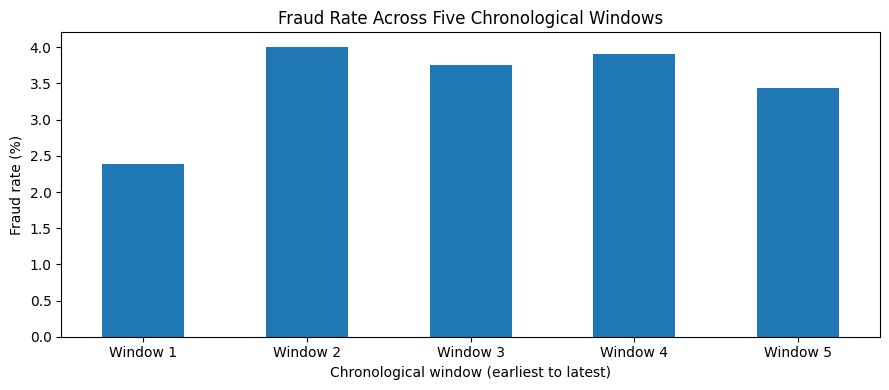

In [9]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Sort transactions by time and reset the row index
time_df = audit_df.sort_values("TransactionDT").reset_index(drop=True).copy()

# Divide the ordered rows into five consecutive windows
n = len(time_df)
window_number = np.minimum(np.arange(n) * 5 // n, 4)

window_labels = [
    "Window 1", "Window 2", "Window 3", "Window 4", "Window 5"
]

time_df["time_window"] = [
    window_labels[i] for i in window_number
]

# Calculate fraud statistics for each window
temporal_summary = (
    time_df.groupby("time_window", sort=False)
    .agg(
        transactions=("isFraud", "size"),
        fraud_cases=("isFraud", "sum"),
        start_time=("TransactionDT", "min"),
        end_time=("TransactionDT", "max")
    )
)

temporal_summary["fraud_rate_percent"] = (
    temporal_summary["fraud_cases"]
    / temporal_summary["transactions"] * 100
)

display(temporal_summary.round(3))

# Plot the fraud rate over time
ax = temporal_summary["fraud_rate_percent"].plot(
    kind="bar",
    figsize=(9, 4),
    title="Fraud Rate Across Five Chronological Windows"
)

ax.set_xlabel("Chronological window (earliest to latest)")
ax.set_ylabel("Fraud rate (%)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()



### Results

The complete training transaction dataset contains 590,540 transactions, divided into five chronological windows of 118,108 transactions each.

The observed fraud rates were:

- Window 1: 2.393%
- Window 2: 4.007%
- Window 3: 3.751%
- Window 4: 3.904%
- Window 5: 3.441%

The highest rate occurred in Window 2 and the lowest in Window 1. The difference was 1.614 percentage points.

### Interpretation

Fraud prevalence varies across the five chronological windows. This motivates further investigation of temporal changes in transaction features and predictive performance.

These descriptive results alone do not establish concept drift or statistical significance.

### Next step

Measure missingness across the transaction features and determine how much of the transaction dataset has matching identity information.

In [10]:

from collections import Counter

# Count missing values in each column, reading 50,000 rows at a time
missing_counts = Counter()
total_rows = 0

start = time.time()

for chunk in pd.read_csv(
    transaction_path,
    chunksize=50000
):
    missing_counts.update(chunk.isna().sum().to_dict())
    total_rows += len(chunk)

missing_summary = pd.DataFrame({
    "missing_count": pd.Series(missing_counts),
    "missing_percent": pd.Series(missing_counts) / total_rows * 100
})

missing_summary = missing_summary.sort_values(
    "missing_percent",
    ascending=False
)

print("Rows examined:", total_rows)
print("Columns examined:", len(missing_summary))
print("Time taken:", round(time.time() - start, 2), "seconds")

print("\nTop 20 columns with the most missing values:")
display(missing_summary.head(20).round(2))

print(
    "\nColumns with no missing values:",
    (missing_summary["missing_count"] == 0).sum()
)

print(
    "Columns with more than 50% missing:",
    (missing_summary["missing_percent"] > 50).sum()
)


Rows examined: 590540
Columns examined: 394
Time taken: 20.36 seconds

Top 20 columns with the most missing values:


,missing_count,missing_percent
dist2,552913,93.63
D7,551623,93.41
D13,528588,89.51
D14,528353,89.47
D12,525823,89.04
D6,517353,87.61
D9,515614,87.31
D8,515614,87.31
V153,508595,86.12
V149,508595,86.12



Columns with no missing values: 20
Columns with more than 50% missing: 174


## Missing-Value Audit

**Method:** Processed the complete transaction CSV in chunks of 50,000 rows and counted missing values across all columns.

**Results:**
- Transactions examined: 590,540
- Columns examined: 394
- Columns with no missing values: 20
- Columns with more than 50% missing values: 174
- Processing time: approximately 20.22 seconds

**Examples of highly incomplete features:**
- dist2: 93.63% missing
- D7: 93.41% missing
- D13: 89.51% missing
- D14: 89.47% missing

**Interpretation:** Missingness is widespread and may affect feature selection, preprocessing, and temporal robustness. Highly incomplete features should be investigated rather than automatically discarded.

**Limitation:** This audit measures overall missingness. It does not establish why values are missing, whether missingness differs between fraud and non-fraud transactions, or whether missingness changes over time.

**Next step:** Determine identity-table coverage and investigate how transaction and identity records are linked.

In [11]:

from pathlib import Path
import pandas as pd

# Find the identity CSV again, in case the session was restarted
identity_files = list(
    Path("/kaggle/input").rglob("train_identity.csv")
)

assert identity_files, "train_identity.csv was not found"

identity_path = identity_files[0]

# Read only transaction IDs from both files
transaction_ids = pd.read_csv(
    transaction_path,
    usecols=["TransactionID"]
)

identity_ids = pd.read_csv(
    identity_path,
    usecols=["TransactionID"]
)

transaction_id_set = set(transaction_ids["TransactionID"])
identity_id_set = set(identity_ids["TransactionID"])

matched_count = len(transaction_id_set & identity_id_set)
unmatched_count = len(transaction_id_set - identity_id_set)

print("Transactions:", len(transaction_id_set))
print("Identity records:", len(identity_id_set))
print("Transactions with identity records:", matched_count)
print("Transactions without identity records:", unmatched_count)

print(
    "Identity coverage (%):",
    round(matched_count / len(transaction_id_set) * 100, 2)
)

print(
    "Transactions without identity (%):",
    round(unmatched_count / len(transaction_id_set) * 100, 2)
)

print(
    "Duplicate IDs in identity table:",
    identity_ids["TransactionID"].duplicated().sum()
)


Transactions: 590540
Identity records: 144233
Transactions with identity records: 144233
Transactions without identity records: 446307
Identity coverage (%): 24.42
Transactions without identity (%): 75.58
Duplicate IDs in identity table: 0


In [12]:

# Mark whether each transaction has a matching identity record
has_identity = audit_df["TransactionID"].isin(
    identity_ids["TransactionID"]
)

# Calculate fraud statistics for the two groups
identity_analysis = audit_df.assign(
    has_identity=has_identity
).groupby("has_identity").agg(
    transactions=("isFraud", "size"),
    fraud_cases=("isFraud", "sum")
)

identity_analysis["fraud_rate_percent"] = (
    identity_analysis["fraud_cases"]
    / identity_analysis["transactions"] * 100
)

identity_analysis.index = identity_analysis.index.map({
    True: "Identity available",
    False: "Identity unavailable"
})

display(identity_analysis.round(3))


,transactions,fraud_cases,fraud_rate_percent
has_identity,,,
Identity unavailable,446307,9345,2.094
Identity available,144233,11318,7.847


In [13]:

from pathlib import Path
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Find the dataset files
# --------------------------------------------------
DATA_ROOT = Path("/kaggle/input/competitions/ieee-fraud-detection")

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_ROOT}\n"
        "Check the dataset path in the Kaggle Input panel."
    )

transaction_path = DATA_ROOT / "train_transaction.csv"
identity_path = DATA_ROOT / "train_identity.csv"
test_path = DATA_ROOT / "test_transaction.csv"

for path in [transaction_path, identity_path, test_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing file: {path}")

print("Dataset files found.")

# --------------------------------------------------
# 2. Read only the five required transaction columns
#    in chunks, while counting missing values across
#    all transaction columns.
# --------------------------------------------------
CORE = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD",
]
CHUNK_SIZE = 50_000
N_WINDOWS = 5

header = pd.read_csv(transaction_path, nrows=0)
missing_columns = [c for c in CORE if c not in header.columns]

if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

missing_counts = pd.Series(0, index=header.columns, dtype="int64")
parts = []

for chunk in pd.read_csv(transaction_path, chunksize=CHUNK_SIZE):
    missing_counts = missing_counts.add(
        chunk.isna().sum(), fill_value=0
    ).astype("int64")

    parts.append(chunk[CORE].copy())

tx = pd.concat(parts, ignore_index=True)
del parts

# --------------------------------------------------
# 3. Verify overall transaction totals
# --------------------------------------------------
n = len(tx)
fraud_count = int(tx["isFraud"].sum())
nonfraud_count = n - fraud_count

print("\n--- Overall transaction audit ---")
print(f"Rows: {n:,}")
print(f"Fraud: {fraud_count:,}")
print(f"Non-fraud: {nonfraud_count:,}")
print(f"Fraud rate: {fraud_count / n:.3%}")
print(f"Duplicate TransactionIDs: {tx['TransactionID'].duplicated().sum():,}")
print(f"TransactionDT range: {tx['TransactionDT'].min():,} to "
      f"{tx['TransactionDT'].max():,}")
print(f"Sorted by TransactionDT: "
      f"{tx['TransactionDT'].is_monotonic_increasing}")
print(f"Unique isFraud values: {sorted(tx['isFraud'].dropna().unique())}")
print(f"Missing values in core columns:\n{tx[CORE].isna().sum()}")

# --------------------------------------------------
# 4. Verify missingness across all 394 columns
# --------------------------------------------------
missing_pct = (missing_counts / n * 100).sort_values(ascending=False)

print("\n--- Missing-value audit ---")
print(f"Columns examined: {len(missing_counts)}")
print(f"Columns with no missing values: {(missing_counts == 0).sum()}")
print(f"Columns with >50% missing: {(missing_pct > 50).sum()}")

print("\nEight columns with the most missing values:")
print(pd.DataFrame({
    "missing_count": missing_counts[missing_pct.index[:8]],
    "missing_percent": missing_pct.head(8).round(2),
}))

# --------------------------------------------------
# 5. Verify identity-table coverage
# --------------------------------------------------
identity_ids = pd.read_csv(
    identity_path,
    usecols=["TransactionID"]
)["TransactionID"]

identity_id_set = set(identity_ids.dropna())

tx["has_identity"] = tx["TransactionID"].isin(identity_id_set)

print("\n--- Identity coverage ---")
print(f"Identity rows: {len(identity_ids):,}")
print(f"Duplicate identity IDs: {identity_ids.duplicated().sum():,}")
print(f"Transactions with identity: {tx['has_identity'].sum():,}")
print(f"Transactions without identity: {(~tx['has_identity']).sum():,}")
print(f"Identity coverage: {tx['has_identity'].mean():.2%}")
print(f"Identity IDs unmatched to transactions: "
      f"{(~identity_ids.isin(set(tx['TransactionID']))).sum():,}")

identity_rates = tx.groupby("has_identity").agg(
    transactions=("isFraud", "size"),
    fraud_cases=("isFraud", "sum"),
)
identity_rates["fraud_rate"] = (
    identity_rates["fraud_cases"] / identity_rates["transactions"]
)

print("\nFraud rate by identity availability:")
print(identity_rates)

# --------------------------------------------------
# 6. Reproduce five equal-count chronological windows
# --------------------------------------------------
tx = tx.sort_values("TransactionDT", kind="stable").reset_index(drop=True)
tx["window"] = (np.arange(n) * N_WINDOWS // n) + 1

window_summary = tx.groupby("window").agg(
    transactions=("isFraud", "size"),
    fraud_cases=("isFraud", "sum"),
    start_time=("TransactionDT", "min"),
    end_time=("TransactionDT", "max"),
    identity_coverage=("has_identity", "mean"),
)

window_summary["fraud_rate"] = (
    window_summary["fraud_cases"] / window_summary["transactions"]
)
window_summary["duration"] = (
    window_summary["end_time"] - window_summary["start_time"]
)

print("\n--- Five chronological windows ---")
print(window_summary.to_string(
    formatters={
        "fraud_rate": "{:.3%}".format,
        "identity_coverage": "{:.2%}".format,
    }
))

print("\nAudit finished.")


Dataset files found.

--- Overall transaction audit ---
Rows: 590,540
Fraud: 20,663
Non-fraud: 569,877
Fraud rate: 3.499%
Duplicate TransactionIDs: 0
TransactionDT range: 86,400 to 15,811,131
Sorted by TransactionDT: True
Unique isFraud values: [np.int64(0), np.int64(1)]
Missing values in core columns:
TransactionID     0
isFraud           0
TransactionDT     0
TransactionAmt    0
ProductCD         0
dtype: int64

--- Missing-value audit ---
Columns examined: 394
Columns with no missing values: 20
Columns with >50% missing: 174

Eight columns with the most missing values:
       missing_count  missing_percent
dist2         552913            93.63
D7            551623            93.41
D13           528588            89.51
D14           528353            89.47
D12           525823            89.04
D6            517353            87.61
D9            515614            87.31
D8            515614            87.31

--- Identity coverage ---
Identity rows: 144,233
Duplicate identity IDs: 0
Tra

--- Equal-duration temporal windows ---
             transactions  fraud_cases  start_time  end_time identity_coverage fraud_rate  duration_observed
time_window                                                                                                 
1                  101927         2596       86400   2051989            41.78%     2.547%            1965589
2                   79669         2608     2051996   4017565            30.77%     3.274%            1965569
3                   69612         2980     4017630   5983054            17.14%     4.281%            1965424
4                   68719         2698     5983357   7948765            19.39%     3.926%            1965408
5                   74459         2729     7948768   9914340            17.41%     3.665%            1965572
6                   67331         2659     9914386  11879927            19.62%     3.949%            1965541
7                   65027         2049    11880026  13845157            17.27%     3.151

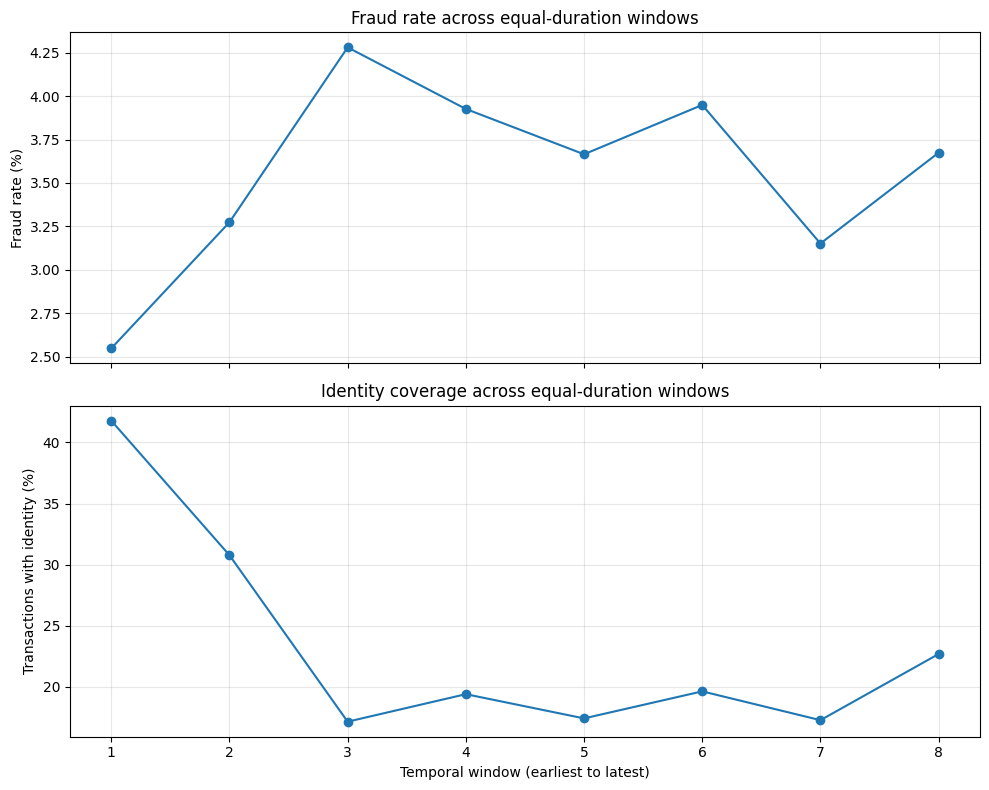

In [14]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check that the required DataFrame exists and has the needed columns.
required = {
    "TransactionDT", "isFraud", "TransactionID", "has_identity"
}
missing = required.difference(tx.columns)

if missing:
    raise ValueError(
        f"tx is missing columns: {sorted(missing)}. "
        "Rerun the successful audit cell first."
    )

# Sort chronologically and work on a separate copy.
time_df = tx.sort_values(
    "TransactionDT", kind="stable"
).copy()

N_INTERVALS = 8

# Divide the observed time range into equal-duration intervals.
time_min = time_df["TransactionDT"].min()
time_max = time_df["TransactionDT"].max()
time_edges = np.linspace(time_min, time_max, N_INTERVALS + 1)

# Include the maximum value in the final interval.
time_df["time_window"] = pd.cut(
    time_df["TransactionDT"],
    bins=time_edges,
    labels=False,
    include_lowest=True
) + 1

# Summarize each interval.
weekly_summary = time_df.groupby(
    "time_window", observed=True
).agg(
    transactions=("TransactionID", "size"),
    fraud_cases=("isFraud", "sum"),
    start_time=("TransactionDT", "min"),
    end_time=("TransactionDT", "max"),
    identity_coverage=("has_identity", "mean")
)

weekly_summary["fraud_rate"] = (
    weekly_summary["fraud_cases"] /
    weekly_summary["transactions"]
)

weekly_summary["duration_observed"] = (
    weekly_summary["end_time"] -
    weekly_summary["start_time"]
)

print("--- Equal-duration temporal windows ---")
print(
    weekly_summary.to_string(
        formatters={
            "fraud_rate": "{:.3%}".format,
            "identity_coverage": "{:.2%}".format
        }
    )
)

# Plot fraud prevalence and identity coverage over time.
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].plot(
    weekly_summary.index,
    weekly_summary["fraud_rate"] * 100,
    marker="o"
)
axes[0].set_title("Fraud rate across equal-duration windows")
axes[0].set_ylabel("Fraud rate (%)")
axes[0].grid(alpha=0.3)

axes[1].plot(
    weekly_summary.index,
    weekly_summary["identity_coverage"] * 100,
    marker="o"
)
axes[1].set_title("Identity coverage across equal-duration windows")
axes[1].set_xlabel("Temporal window (earliest to latest)")
axes[1].set_ylabel("Transactions with identity (%)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [15]:

# Confirm the previous analysis is available.
required = {"time_window", "ProductCD", "isFraud", "has_identity"}
missing = required.difference(time_df.columns)

if missing:
    raise ValueError(
        f"time_df is missing {sorted(missing)}. "
        "Rerun the previous equal-duration window cell."
    )

# Fraud rates by time window and product category.
product_summary = time_df.groupby(
    ["time_window", "ProductCD"], observed=True
).agg(
    transactions=("isFraud", "size"),
    fraud_cases=("isFraud", "sum"),
    identity_coverage=("has_identity", "mean")
).reset_index()

product_summary["fraud_rate"] = (
    product_summary["fraud_cases"] /
    product_summary["transactions"]
)

print("--- Fraud rate and identity coverage by window and ProductCD ---")
print(
    product_summary.to_string(
        index=False,
        formatters={
            "fraud_rate": "{:.3%}".format,
            "identity_coverage": "{:.2%}".format
        }
    )
)

# Overall transaction counts by ProductCD and window.
print("\n--- Transaction volume by ProductCD and window ---")
print(
    time_df.pivot_table(
        index="time_window",
        columns="ProductCD",
        values="TransactionID",
        aggfunc="count",
        fill_value=0,
        observed=True
    )
)


--- Fraud rate and identity coverage by window and ProductCD ---
 time_window ProductCD  transactions  fraud_cases identity_coverage fraud_rate
           1         C         11579         1009            86.34%     8.714%
           1         H         15872          311            99.68%     1.959%
           1         R         14283          148            99.61%     1.036%
           1         S          2547           61            99.73%     2.395%
           1         W         57646         1067             0.00%     1.851%
           2         C         10281         1039            89.29%    10.106%
           2         H          6593          262            99.64%     3.974%
           2         R          7678          234            99.65%     3.048%
           2         S          1116           72            99.64%     6.452%
           2         W         54001         1001             0.00%     1.854%
           3         C          7529         1064            90.37

--- Missing percentage by feature and window ---
       Window 1  Window 2  Window 3  Window 4  Window 5  Window 6  Window 7  Window 8
dist2      91.7      92.3      94.0      90.0      96.5      94.9      95.9      94.8
D7         93.9      93.0      94.0      93.1      94.4      93.4      94.4      90.7
D13        90.4      88.6      90.3      89.3      89.5      89.2      91.3      87.1
D14        88.8      88.3      90.5      89.6      89.9      89.7      91.5      87.9
D12        89.5      87.1      89.2      88.1      90.4      88.2      90.9      89.0
D6         87.2      85.7      88.5      87.3      89.7      87.4      89.8      85.7
D9         78.2      85.6      91.2      89.6      90.6      90.3      90.8      86.9
D8         78.2      85.6      91.2      89.6      90.6      90.3      90.8      86.9
V153       68.0      80.7      92.6      91.5      93.3      92.7      91.6      88.0
V149       68.0      80.7      92.6      91.5      93.3      92.7      91.6      88.0
V141 

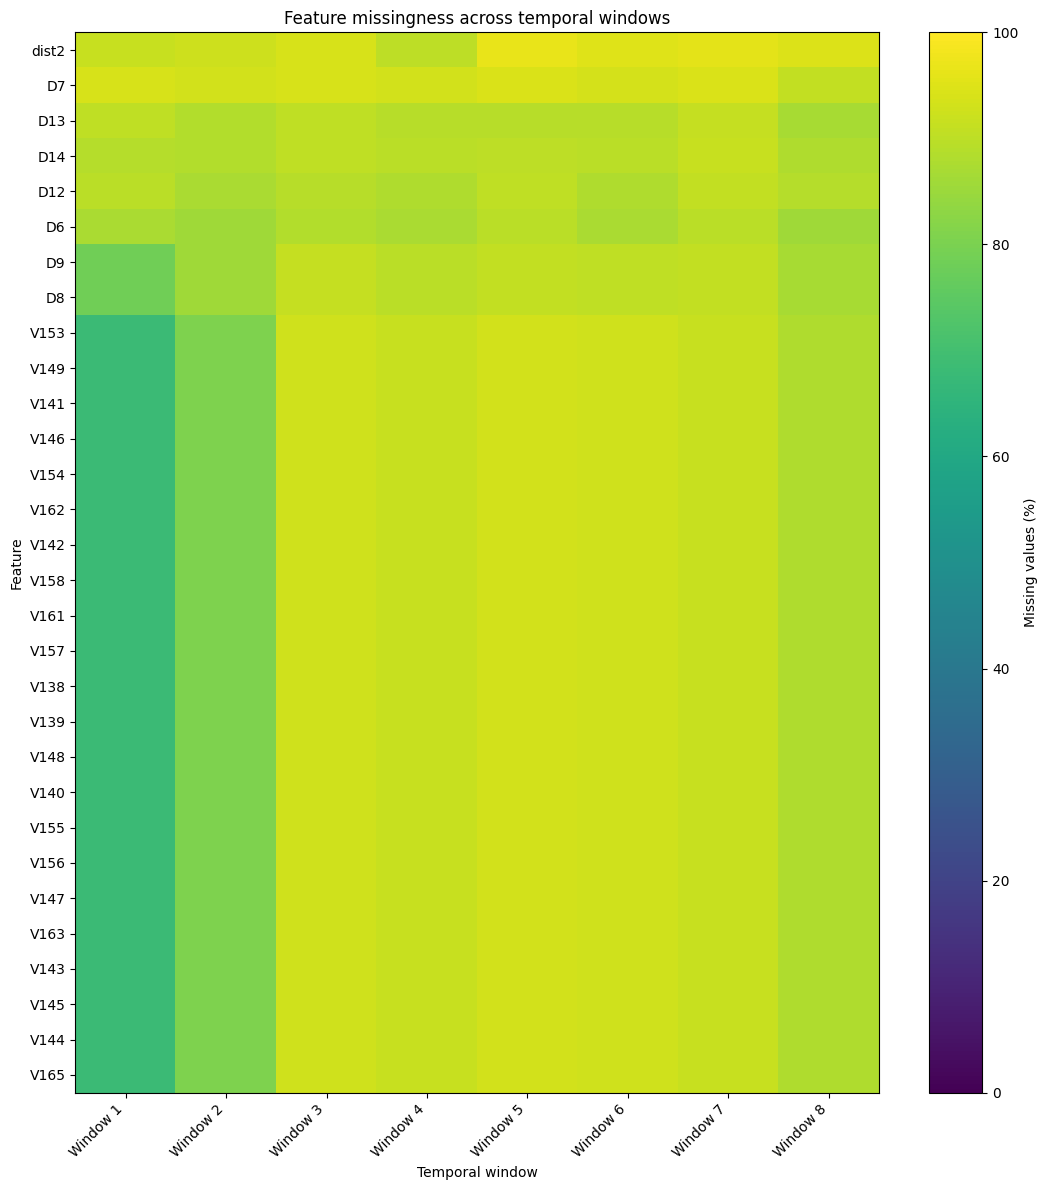


--- D8/D9 co-missingness ---
Both missing: 515,614
Only D8 missing: 0
Only D9 missing: 0
Neither missing: 74,926


In [16]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_ROOT = Path("/kaggle/input/competitions/ieee-fraud-detection")
transaction_path = DATA_ROOT / "train_transaction.csv"

# Select the 30 most incomplete features using the audit results.
if "missing_counts" not in globals():
    raise ValueError(
        "missing_counts is unavailable. Rerun the audit cell first."
    )

feature_names = (
    missing_counts.sort_values(ascending=False)
    .head(30)
    .index.tolist()
)

# Read only TransactionID, TransactionDT, and selected features.
needed_cols = list(dict.fromkeys(
    ["TransactionID", "TransactionDT"] + feature_names
))

feature_parts = []

for chunk in pd.read_csv(
    transaction_path,
    usecols=needed_cols,
    chunksize=50_000
):
    feature_parts.append(chunk)

feature_df = pd.concat(feature_parts, ignore_index=True)
del feature_parts

# Attach the time-window labels created in the previous analysis.
window_lookup = time_df[
    ["TransactionID", "time_window"]
].drop_duplicates("TransactionID")

feature_df = feature_df.merge(
    window_lookup,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

# Percentage missing for each feature in each time window.
missing_by_window = feature_df.groupby(
    "time_window", observed=True
)[feature_names].agg(
    lambda column: column.isna().mean() * 100
).T

missing_by_window.columns = [
    f"Window {int(c)}" for c in missing_by_window.columns
]

print("--- Missing percentage by feature and window ---")
print(missing_by_window.round(1).to_string())

# Heatmap: rows are features, columns are windows.
fig, ax = plt.subplots(figsize=(11, 12))

image = ax.imshow(
    missing_by_window.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(missing_by_window.columns)))
ax.set_xticklabels(missing_by_window.columns, rotation=45, ha="right")
ax.set_yticks(range(len(missing_by_window.index)))
ax.set_yticklabels(missing_by_window.index)
ax.set_title("Feature missingness across temporal windows")
ax.set_xlabel("Temporal window")
ax.set_ylabel("Feature")

fig.colorbar(image, ax=ax, label="Missing values (%)")
plt.tight_layout()
plt.show()

# Check whether D8 and D9 are missing on exactly the same rows.
d_cols = ["D8", "D9"]
if all(c in feature_df.columns for c in d_cols):
    d8_missing = feature_df["D8"].isna()
    d9_missing = feature_df["D9"].isna()

    print("\n--- D8/D9 co-missingness ---")
    print(f"Both missing: {(d8_missing & d9_missing).sum():,}")
    print(f"Only D8 missing: {(d8_missing & ~d9_missing).sum():,}")
    print(f"Only D9 missing: {(~d8_missing & d9_missing).sum():,}")
    print(f"Neither missing: {(~d8_missing & ~d9_missing).sum():,}")
else:
    print("\nD8 or D9 was not included in the selected feature columns.")


In [17]:

# Check that the previous analysis is still available.
required = {"isFraud", "ProductCD", "TransactionID"}
missing = required.difference(time_df.columns)

if missing:
    raise ValueError(
        f"time_df is missing {sorted(missing)}. "
        "Rerun the earlier audit cells."
    )

if "feature_df" not in globals():
    raise ValueError(
        "feature_df is unavailable. Rerun the missingness analysis cell."
    )

# Select a small group of features spanning D and V families.
candidate_features = [
    "dist2", "D7", "D13", "D14", "D8", "D9",
    "V153", "V149", "V141"
]

available_features = [
    c for c in candidate_features if c in feature_df.columns
]

if not available_features:
    raise ValueError("None of the candidate features are available.")

# Add fraud labels by TransactionID without changing row order.
labels = time_df[["TransactionID", "isFraud"]].drop_duplicates(
    "TransactionID"
)

analysis_df = feature_df[
    ["TransactionID"] + available_features
].merge(
    labels,
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

# Calculate missingness separately for fraud and non-fraud.
results = []

for col in available_features:
    for fraud_value, group in analysis_df.groupby("isFraud"):
        results.append({
            "feature": col,
            "isFraud": int(fraud_value),
            "transactions": len(group),
            "missing_count": int(group[col].isna().sum()),
            "missing_percent": group[col].isna().mean() * 100
        })

missing_by_label = pd.DataFrame(results)

print("--- Feature missingness by fraud label ---")
print(
    missing_by_label.pivot(
        index="feature",
        columns="isFraud",
        values="missing_percent"
    ).rename(columns={
        0: "nonfraud_missing_pct",
        1: "fraud_missing_pct"
    }).round(2).to_string()
)


--- Feature missingness by fraud label ---
isFraud  nonfraud_missing_pct  fraud_missing_pct
feature                                         
D13                     90.33              66.91
D14                     90.35              65.09
D7                      94.19              71.98
D8                      88.23              62.12
D9                      88.23              62.12
V141                    86.26              82.34
V149                    86.26              82.34
V153                    86.26              82.34
dist2                   94.05              81.94


In [18]:

import numpy as np
import pandas as pd

# Check that the audited transaction DataFrame is available.
required = {"TransactionID", "TransactionDT", "isFraud"}
missing = required.difference(tx.columns)

if missing:
    raise ValueError(
        f"tx is missing columns: {sorted(missing)}. "
        "Rerun your successful dataset-audit cell first."
    )

# Sort chronologically.
model_df = tx.sort_values(
    "TransactionDT", kind="stable"
).reset_index(drop=True).copy()

# Calculate chronological split boundaries.
n = len(model_df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

# Create separate chronological periods.
train_df = model_df.iloc[:train_end].copy()
valid_df = model_df.iloc[train_end:valid_end].copy()
test_df = model_df.iloc[valid_end:].copy()

# Summarize each period.
split_summary = []

for name, df in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df),
]:
    split_summary.append({
        "split": name,
        "transactions": len(df),
        "fraud_cases": int(df["isFraud"].sum()),
        "fraud_rate_pct": df["isFraud"].mean() * 100,
        "start_TransactionDT": df["TransactionDT"].min(),
        "end_TransactionDT": df["TransactionDT"].max(),
    })

split_summary = pd.DataFrame(split_summary)

print("--- Chronological split summary ---")
print(split_summary.to_string(
    index=False,
    formatters={"fraud_rate_pct": "{:.3f}%".format}
))

# Confirm that the periods do not overlap in row order.
assert len(train_df) + len(valid_df) + len(test_df) == n
assert train_df["TransactionDT"].max() <= valid_df["TransactionDT"].min()
assert valid_df["TransactionDT"].max() <= test_df["TransactionDT"].min()

print("\nChecks passed: all rows assigned and periods ordered chronologically.")



--- Chronological split summary ---
     split  transactions  fraud_cases fraud_rate_pct  start_TransactionDT  end_TransactionDT
     Train        413378        14538         3.517%                86400           10437996
Validation         88581         3042         3.434%             10438003           13151840
      Test         88581         3083         3.480%             13151880           15811131

Checks passed: all rows assigned and periods ordered chronologically.


In [19]:

from pathlib import Path
import pandas as pd
import numpy as np
import gc

# 1. Locate the labelled training files.
DATA_DIR = Path("/kaggle/input/competitions/ieee-fraud-detection")
transaction_path = DATA_DIR / "train_transaction.csv"
identity_path = DATA_DIR / "train_identity.csv"

for path in [transaction_path, identity_path]:
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

# 2. Load transaction features in chunks.
# The full transaction table has 394 columns.
chunks = []

for chunk in pd.read_csv(transaction_path, chunksize=50_000):
    chunks.append(chunk)

transactions_full = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()

print("Transaction table:", transactions_full.shape)

# 3. Load the identity table.
identity_full = pd.read_csv(identity_path)
print("Identity table:", identity_full.shape)

# 4. Check join safety before merging.
assert transactions_full["TransactionID"].is_unique
assert identity_full["TransactionID"].is_unique
assert transactions_full["isFraud"].notna().all()

# 5. Merge identity features onto transactions.
model_data = transactions_full.merge(
    identity_full,
    on="TransactionID",
    how="left",
    validate="one_to_one",
    suffixes=("", "_identity")
)

del transactions_full, identity_full
gc.collect()

# 6. Preserve chronological ordering and recreate the same split.
model_data = model_data.sort_values(
    "TransactionDT", kind="stable"
).reset_index(drop=True)

n = len(model_data)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train_df = model_data.iloc[:train_end].copy()
valid_df = model_data.iloc[train_end:valid_end].copy()
test_df = model_data.iloc[valid_end:].copy()

# 7. Define target and initial predictor columns.
TARGET = "isFraud"
EXCLUDE = {"TransactionID", TARGET, "TransactionDT"}

feature_cols = [
    col for col in model_data.columns
    if col not in EXCLUDE
]

# 8. Verify the dataset and split.
print("\n--- Modelling dataset check ---")
print("Combined dataset shape:", model_data.shape)
print("Number of predictor columns:", len(feature_cols))
print("Train shape:", train_df.shape)
print("Validation shape:", valid_df.shape)
print("Test shape:", test_df.shape)

print("\nFraud cases:")
print("Train:", int(train_df[TARGET].sum()))
print("Validation:", int(valid_df[TARGET].sum()))
print("Test:", int(test_df[TARGET].sum()))

print("\nTarget values:", sorted(model_data[TARGET].unique()))
print("Duplicate transaction IDs:", model_data["TransactionID"].duplicated().sum())
print("Chronological order:", model_data["TransactionDT"].is_monotonic_increasing)

print("\nFirst 15 predictor columns:")
print(feature_cols[:15])

assert len(model_data) == 590_540
assert model_data["TransactionID"].is_unique
assert set(model_data[TARGET].unique()).issubset({0, 1})
assert len(train_df) + len(valid_df) + len(test_df) == len(model_data)

print("\nModelling dataset checks passed.")


Transaction table: (590540, 394)
Identity table: (144233, 41)

--- Modelling dataset check ---
Combined dataset shape: (590540, 434)
Number of predictor columns: 431
Train shape: (413378, 434)
Validation shape: (88581, 434)
Test shape: (88581, 434)

Fraud cases:
Train: 14538
Validation: 3042
Test: 3083

Target values: [np.int64(0), np.int64(1)]
Duplicate transaction IDs: 0
Chronological order: True

First 15 predictor columns:
['TransactionAmt', 'ProductCD', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'P_emaildomain', 'R_emaildomain', 'C1']

Modelling dataset checks passed.


In [20]:

# Inspect feature types and missingness.
X_train = train_df[feature_cols]

dtype_summary = X_train.dtypes.astype(str).value_counts()
print("--- Feature data types in training period ---")
print(dtype_summary.to_string())

feature_audit = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "missing_pct": X_train.isna().mean() * 100,
    "unique_values": X_train.nunique(dropna=True)
})

print("\n--- Most incomplete predictor columns ---")
print(
    feature_audit.sort_values("missing_pct", ascending=False)
    .head(15)
    .round(2)
    .to_string()
)

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=[np.number, "bool"]
).columns.tolist()

print("\nNumeric columns:", len(numeric_cols))
print("Categorical/text columns:", len(categorical_cols))
print("\nCategorical examples:", categorical_cols[:25])

# Verify that the target and identifiers are excluded.
assert "isFraud" not in feature_cols
assert "TransactionID" not in feature_cols
assert "TransactionDT" not in feature_cols

print("\nFeature inspection complete.")


--- Feature data types in training period ---
float64    399
object      31
int64        1

--- Most incomplete predictor columns ---
         dtype  missing_pct  unique_values
id_24  float64        99.13             10
id_25  float64        99.05            307
id_08  float64        99.05             93
id_07  float64        99.05             81
id_26  float64        99.05             85
id_21  float64        99.05            421
id_22  float64        99.05             23
id_27   object        99.05              2
id_23   object        99.05              3
D7     float64        93.53            549
dist2  float64        92.95           1598
id_18  float64        91.77             18
D13    float64        89.34            512
D14    float64        89.12            740
D12    float64        88.56            583

Numeric columns: 400
Categorical/text columns: 31

Categorical examples: ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M

In [21]:
import time
import pandas as pd
import numpy as np

DATA_DIR = "/kaggle/input/competitions/ieee-fraud-detection"
t0 = time.time()

trans = pd.read_csv(f"{DATA_DIR}/train_transaction.csv")
print("transactions loaded:", trans.shape, "|", round(time.time() - t0), "seconds")

ident = pd.read_csv(f"{DATA_DIR}/train_identity.csv")
print("identity loaded:", ident.shape, "|", round(time.time() - t0), "seconds")

# Join: keep every transaction, add identity info where it exists
df = trans.merge(ident, on="TransactionID", how="left")
del trans, ident                      # free memory

# Use smaller number types (halves memory, no meaningful loss)
for c in df.select_dtypes("float64").columns:
    if c != "TransactionAmt":
        df[c] = df[c].astype("float32")

# Sort by time
df = df.sort_values("TransactionDT").reset_index(drop=True)

print("Rows, columns:", df.shape)
print("Memory (GB):", round(df.memory_usage().sum() / 1e9, 2))

# Weekly counts
df["week"] = ((df["TransactionDT"] / 86400 - 1) // 7).astype(int)
weekly = df.groupby("week")["isFraud"].agg(transactions="size", frauds="sum")
weekly["fraud_rate_%"] = (weekly["frauds"] / weekly["transactions"] * 100).round(2)
print(weekly)

transactions loaded: (590540, 394) | 23 seconds
identity loaded: (144233, 41) | 23 seconds
Rows, columns: (590540, 434)
Memory (GB): 1.11
      transactions  frauds  fraud_rate_%
week                                    
0            27596     804          2.91
1            28463     717          2.52
2            35701     869          2.43
3            34906     724          2.07
4            24539     889          3.62
5            20919     803          3.84
6            20564     823          4.00
7            19761     862          4.36
8            21432     927          4.33
9            22534     996          4.42
10           20953     880          4.20
11           20175     676          3.35
12           22391     912          4.07
13           27429     884          3.22
14           21269     718          3.38
15           20891     866          4.15
16           21078    1069          5.07
17           23575     833          3.53
18           19258     727          3.78
1

In [22]:
miss = (df.isna().mean() * 100).round(1)

def family(c):
    if c.startswith("V"): return "V"
    if c.startswith("C") and c[1:].isdigit(): return "C"
    if c.startswith("D") and c[1:].isdigit(): return "D"
    if c.startswith("M") and c[1:].isdigit(): return "M"
    if c.startswith("id_") or c in ("DeviceType", "DeviceInfo"): return "identity"
    if c.startswith("card"): return "card"
    return "other"

summary = pd.DataFrame({"missing_%": miss, "family": [family(c) for c in miss.index]})

bins = [-1, 0, 20, 50, 80, 95, 100]
labels = ["0%", "0-20%", "20-50%", "50-80%", "80-95%", "95-100%"]
summary["bucket"] = pd.cut(summary["missing_%"], bins=bins, labels=labels)
print(pd.crosstab(summary["family"], summary["bucket"]))

print(summary.groupby("family")["missing_%"].mean().round(1))

bucket    0%  0-20%  20-50%  50-80%  80-95%  95-100%
family                                              
C         14      0       0       0       0        0
D          0      3       4       1       7        0
M          0      0       5       4       0        0
V         32    119      29     112      47        0
card       1      5       0       0       0        0
identity   0      0       0      21      10        9
other      6      3       0       2       1        0
family
C            0.0
D           58.1
M           49.9
V           43.1
card         0.5
identity    84.5
other       22.4
Name: missing_%, dtype: float64


In [23]:
y = df["isFraud"].values
skip = {"isFraud", "TransactionID", "TransactionDT", "week"}

rows = []
for c in df.columns:
    if c in skip:
        continue
    m = df[c].isna().values            # True where the value is missing
    if m.mean() < 0.01 or m.mean() > 0.99:
        continue                       # skip columns that are almost never / always missing
    rows.append({
        "column": c,
        "missing_%": round(m.mean() * 100, 1),
        "fraud_rate_when_missing_%": round(y[m].mean() * 100, 2),
        "fraud_rate_when_present_%": round(y[~m].mean() * 100, 2),
    })

res = pd.DataFrame(rows)
res["difference"] = (res["fraud_rate_when_missing_%"] - res["fraud_rate_when_present_%"]).round(2)
res = res.reindex(res["difference"].abs().sort_values(ascending=False).index)

print("Overall fraud rate: %.2f%%" % (y.mean() * 100))
print(res.head(15).to_string(index=False))

Overall fraud rate: 3.50%
column  missing_%  fraud_rate_when_missing_%  fraud_rate_when_present_%  difference
    D7       93.4                       2.70                      14.88      -12.18
 addr2       11.1                      11.78                       2.46        9.32
 addr1       11.1                      11.78                       2.46        9.32
   D12       89.0                       2.48                      11.74       -9.26
   D14       89.5                       2.55                      11.60       -9.05
   D13       89.5                       2.62                      11.04       -8.42
 id_04       88.8                       2.59                      10.72       -8.13
 id_03       88.8                       2.59                      10.72       -8.13
    D6       87.6                       2.50                      10.55       -8.05
 id_09       87.3                       2.49                      10.45       -7.96
 id_10       87.3                       2.49      

In [24]:
# 1. Convert seconds to days
df["day"] = df["TransactionDT"] / 86400 - 1

# 2. Define the three periods
train_mask = (df["day"] >= 7)   & (df["day"] < 91)
val_mask   = (df["day"] >= 91)  & (df["day"] < 105)
test_mask  =  df["day"] >= 105

split_summary = pd.DataFrame({
    "rows":   [train_mask.sum(), val_mask.sum(), test_mask.sum()],
    "frauds": [df.loc[train_mask, "isFraud"].sum(),
               df.loc[val_mask,   "isFraud"].sum(),
               df.loc[test_mask,  "isFraud"].sum()],
}, index=["train", "validation", "test"])
split_summary["fraud_rate_%"] = (split_summary["frauds"] / split_summary["rows"] * 100).round(2)
print(split_summary)

# 3. Column rules, checked on TRAINING rows only
not_features = ["isFraud", "TransactionID", "TransactionDT", "week", "day"]
candidates = [c for c in df.columns if c not in not_features]
train = df.loc[train_mask, candidates]

missing_frac = train.isna().mean()
n_unique = train.nunique()

too_empty = missing_frac[missing_frac > 0.95].index.tolist()
constant  = n_unique[n_unique <= 1].index.tolist()

print("\nColumns more than 95% missing in training:", len(too_empty), too_empty)
print("Constant columns in training:", len(constant), constant)
print("Columns remaining:", len(candidates) - len(set(too_empty + constant)))

              rows  frauds  fraud_rate_%
train       292338   10078          3.45
validation   48698    1602          3.29
test        221908    8179          3.69

Columns more than 95% missing in training: 9 ['id_07', 'id_08', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']
Constant columns in training: 2 ['V1', 'V107']
Columns remaining: 420


In [25]:
# 1. The V columns that survived the earlier rules
v_cols = [c for c in candidates
          if c.startswith("V") and c[1:].isdigit()
          and c not in too_empty and c not in constant]
print("V columns before pruning:", len(v_cols))

# 2. Correlation between V columns, using a 100,000-row sample of the TRAINING period
sample = df.loc[train_mask, v_cols].sample(100_000, random_state=42)
corr = sample.corr().abs()          # table: how similar is each column to each other column

# 3. Go through the columns in order; keep one only if it's not too similar to one already kept
kept = []
for c in v_cols:
    if all(corr.loc[c, k] <= 0.95 for k in kept):
        kept.append(c)
dropped_v = [c for c in v_cols if c not in kept]
print("V columns kept:", len(kept), "| dropped as duplicates:", len(dropped_v))

# 4. Our final list of columns
feature_cols = [c for c in candidates
                if c not in too_empty and c not in constant and c not in dropped_v]
print("Total feature columns now:", len(feature_cols))

# 5. Quick check on what the list contains
text_cols = [c for c in feature_cols if df[c].dtype == "object"]
print("Text (non-number) columns:", len(text_cols))
print(text_cols)

V columns before pruning: 337
V columns kept: 124 | dropped as duplicates: 213
Total feature columns now: 207
Text (non-number) columns: 29
['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']


In [26]:
# 1. How many different values does each text column have?
print(df[text_cols].nunique().sort_values(ascending=False))

# 2. Build X (the table of inputs) with text replaced by codes
X = df[feature_cols].copy()
for c in text_cols:
    codes, uniques = pd.factorize(X[c])      # numbers in order of first appearance; missing -> -1
    codes = codes.astype("float32")
    codes[codes < 0] = np.nan                # keep "missing" as missing
    X[c] = codes

X = X.astype("float32")                      # smaller memory
y = df["isFraud"].values                     # the answer column (1 = fraud)

print("\nX shape:", X.shape)
print(X.dtypes.value_counts())

# 3. See what the conversion looks like for e-mail domains
peek = pd.DataFrame({"text": df["P_emaildomain"], "code": X["P_emaildomain"]})
print(peek.dropna().drop_duplicates().head(8))

DeviceInfo       1786
id_33             260
id_31             130
id_30              75
R_emaildomain      60
P_emaildomain      59
ProductCD           5
card6               4
id_34               4
card4               4
M4                  3
id_15               3
M1                  2
M8                  2
M7                  2
M6                  2
M5                  2
M3                  2
M2                  2
id_16               2
M9                  2
id_28               2
id_29               2
id_12               2
id_35               2
id_36               2
id_37               2
id_38               2
DeviceType          2
dtype: int64

X shape: (590540, 207)
float32    207
Name: count, dtype: int64
             text  code
1       gmail.com   0.0
2     outlook.com   1.0
3       yahoo.com   2.0
7        mail.com   3.0
8   anonymous.com   4.0
11    hotmail.com   5.0
12    verizon.net   6.0
13        aol.com   7.0


In [27]:
import lightgbm as lgb
from sklearn.metrics import average_precision_score

# 1. Split the table into the three periods
X_train, y_train = X[train_mask], y[train_mask]
X_val,   y_val   = X[val_mask],   y[val_mask]
X_test,  y_test  = X[test_mask],  y[test_mask]

# 2. Create the model
model = lgb.LGBMClassifier(
    n_estimators=1000,        # maximum number of trees
    learning_rate=0.05,
    num_leaves=64,
    colsample_bytree=0.5,     # each tree sees half of the columns
    subsample=0.8, subsample_freq=1,
    scale_pos_weight=5,       # gives fraud examples extra weight (fraud is rare)
    metric="average_precision",
    random_state=42,
    verbose=-1,
)

# 3. Train, stopping when validation PR-AUC stops improving for 50 rounds
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False)],
)
print("Trees used:", model.best_iteration_)

# 4. Score validation and test
val_score  = model.predict_proba(X_val)[:, 1]
test_score = model.predict_proba(X_test)[:, 1]
print("PR-AUC validation:", round(average_precision_score(y_val, val_score), 3))
print("PR-AUC future test (all weeks):", round(average_precision_score(y_test, test_score), 3))

# 5. PR-AUC for each future week
test_df = pd.DataFrame({"week": df.loc[test_mask, "week"].values,
                        "y": y_test, "score": test_score})
rows = []
for w, g in test_df.groupby("week"):
    rows.append({"week": w, "transactions": len(g), "frauds": int(g["y"].sum()),
                 "PR_AUC": round(average_precision_score(g["y"], g["score"]), 3)})
print(pd.DataFrame(rows).to_string(index=False))

Trees used: 641
PR-AUC validation: 0.549
PR-AUC future test (all weeks): 0.523
 week  transactions  frauds  PR_AUC
   15         20891     866   0.591
   16         21078    1069   0.619
   17         23575     833   0.639
   18         19258     727   0.479
   19         18572     611   0.488
   20         18549     639   0.403
   21         21443     660   0.501
   22         19811     565   0.448
   23         21038     729   0.447
   24         19941     733   0.525
   25         17752     747   0.509


In [28]:
from sklearn.model_selection import train_test_split

# ---------- Part A: random split, same model settings ----------
idx = np.arange(len(y))
tr_i, rest_i = train_test_split(idx, test_size=0.30, random_state=42, stratify=y)
va_i, te_i   = train_test_split(rest_i, test_size=2/3, random_state=42, stratify=y[rest_i])
# -> 70% train, 10% validation, 20% test, all mixed across time

model_r = lgb.LGBMClassifier(
    n_estimators=1000, learning_rate=0.05, num_leaves=64, colsample_bytree=0.5,
    subsample=0.8, subsample_freq=1, scale_pos_weight=5,
    metric="average_precision", random_state=42, verbose=-1)
model_r.fit(X.iloc[tr_i], y[tr_i],
            eval_set=[(X.iloc[va_i], y[va_i])],
            callbacks=[lgb.early_stopping(50, verbose=False)])

pr_random = average_precision_score(y[te_i], model_r.predict_proba(X.iloc[te_i])[:, 1])
pr_future = average_precision_score(y_test, test_score)
print("PR-AUC with RANDOM split :", round(pr_random, 3))
print("PR-AUC with TIME split   :", round(pr_future, 3))
print("The random split looks", round((pr_random / pr_future - 1) * 100), "% better")

# ---------- Part B: is the early-vs-late drop real? (bootstrap) ----------
early = test_df[test_df.week.isin([15, 16, 17])]
late  = test_df[test_df.week.isin([23, 24, 25])]
rng = np.random.RandomState(0)
diffs = []
for _ in range(200):
    e = early.sample(len(early), replace=True, random_state=rng.randint(1e9))
    l = late.sample(len(late),  replace=True, random_state=rng.randint(1e9))
    diffs.append(average_precision_score(e.y, e.score) - average_precision_score(l.y, l.score))
print("\nEarly (weeks 15-17) PR-AUC:", round(average_precision_score(early.y, early.score), 3))
print("Late  (weeks 23-25) PR-AUC:", round(average_precision_score(late.y, late.score), 3))
print("Drop = %.3f, 95%% range: %.3f to %.3f" % (np.mean(diffs), np.quantile(diffs, .025), np.quantile(diffs, .975)))

PR-AUC with RANDOM split : 0.816
PR-AUC with TIME split   : 0.523
The random split looks 56 % better

Early (weeks 15-17) PR-AUC: 0.617
Late  (weeks 23-25) PR-AUC: 0.493
Drop = 0.122, 95% range: 0.096 to 0.151


In [29]:
# ---------- PSI function ----------
def psi(ref, cur, bins=10):
    r = ref[~np.isnan(ref)]; c = cur[~np.isnan(cur)]
    if len(r) == 0 or len(c) == 0:
        return np.nan
    edges = np.unique(np.quantile(r, np.linspace(0, 1, bins + 1)))[1:-1]   # decile edges from the reference
    nb = len(edges) + 1
    rc = np.bincount(np.searchsorted(edges, r, side="right"), minlength=nb).astype(float)
    cc = np.bincount(np.searchsorted(edges, c, side="right"), minlength=nb).astype(float)
    rc = np.append(rc, np.isnan(ref).sum())      # one extra bin for "missing"
    cc = np.append(cc, np.isnan(cur).sum())
    rp = np.clip(rc / rc.sum(), 1e-4, None)
    cp = np.clip(cc / cc.sum(), 1e-4, None)
    return float(np.sum((cp - rp) * np.log(cp / rp)))

# ---------- Prepare the data ----------
Xtr = X[train_mask].values
wk_tr = df.loc[train_mask, "week"].values
Xte = X[test_mask].values
wk_te = df.loc[test_mask, "week"].values
test_weeks = sorted(np.unique(wk_te))
train_weeks = sorted(np.unique(wk_tr))

rows = []
for j, col in enumerate(X.columns):
    a = Xtr[:, j]
    # drift: each future week vs the whole training period
    drift = [psi(a, Xte[wk_te == w, j]) for w in test_weeks]
    # noise floor: each training week vs the rest of training
    noise = [psi(a[wk_tr != w], a[wk_tr == w]) for w in train_weeks]
    rows.append({"feature": col,
                 "psi_future": np.nanmean(drift),
                 "noise_floor": np.nanquantile(noise, 0.95)})

res = pd.DataFrame(rows)
res["excess"] = (res["psi_future"] - res["noise_floor"]).clip(lower=0)
res["family"] = res["feature"].map(family)
res = res.sort_values("excess", ascending=False).reset_index(drop=True)

print("Top 15 drifting features (PSI above their own noise floor):")
print(res.head(15).round(3).to_string(index=False))

print("\nFeatures with PSI > 0.1 and above noise:", int(((res.psi_future > 0.1) & (res.excess > 0)).sum()),
      "of", len(res))
print("Features with PSI > 0.25 and above noise:", int(((res.psi_future > 0.25) & (res.excess > 0)).sum()))
print("\nAverage excess PSI by family:")
print(res.groupby("family")["excess"].mean().round(3).sort_values(ascending=False))

Top 15 drifting features (PSI above their own noise floor):
feature  psi_future  noise_floor  excess family
     M9       0.516        0.163   0.354      M
     M8       0.516        0.163   0.354      M
     M7       0.516        0.163   0.354      M
     M1       0.451        0.111   0.339      M
     M3       0.451        0.111   0.339      M
     M2       0.451        0.111   0.339      M
    D11       0.428        0.114   0.314      D
     V4       0.399        0.113   0.286      V
     V5       0.399        0.113   0.286      V
     V8       0.397        0.112   0.286      V
     V9       0.397        0.112   0.286      V
     V2       0.397        0.112   0.286      V
     V7       0.397        0.112   0.286      V
     V3       0.397        0.112   0.286      V
     V6       0.397        0.112   0.286      V

Features with PSI > 0.1 and above noise: 17 of 207
Features with PSI > 0.25 and above noise: 17

Average excess PSI by family:
family
M           0.231
V           0.024
D

        M1    M7    V2    V4   D11  addr1
week                                     
0     61.2  79.7  70.9  70.9  70.9    6.3
1     67.5  83.5  67.4  67.4  67.4    5.0
2     73.7  86.7  73.6  73.6  73.6   13.3
3     74.8  87.6  74.8  74.8  74.8   14.2
4     56.0  77.5  56.0  56.0  56.0   13.9
5     54.3  76.8  54.3  54.3  54.3   11.3
6     59.7  74.1  59.7  59.7  59.7    9.3
7     63.7  72.0  63.7  63.7  63.7   10.8
8     58.8  67.0  58.9  58.9  58.9   11.6
9     52.6  63.8  52.6  52.6  52.6   11.8
10    53.2  63.5  54.5  54.5  54.5   12.5
11    49.6  60.7  49.6  49.6  49.6   12.7
12    45.7  56.0  45.7  45.7  45.7   11.9
13    29.9  39.2  30.0  30.0  30.0    9.1
14    27.9  43.5  29.8  29.8  29.8   11.1
15    29.5  38.6  29.5  29.5  29.5   13.5
16    33.3  42.1  33.3  33.3  33.3   18.1
17    25.1  35.3  25.1  25.1  25.1   10.5
18    26.5  36.9  43.2  43.2  43.2   10.4
19    29.6  46.5  35.2  35.2  35.2   11.0
20    25.3  42.5  27.6  27.6  27.6    8.8
21    26.2  36.9  26.2  26.2  26.2

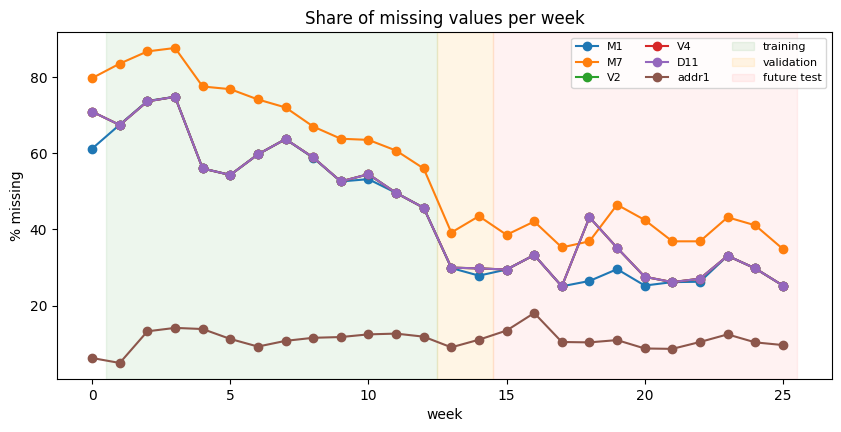

In [30]:
import matplotlib.pyplot as plt

check = ["M1", "M7", "V2", "V4", "D11", "addr1"]    # addr1 = stable control
weekly_missing = pd.DataFrame(
    {c: df[c].isna().groupby(df["week"]).mean() * 100 for c in check}
).round(1)
print(weekly_missing.to_string())

ax = weekly_missing.plot(figsize=(10, 4.5), marker="o")
ax.axvspan(0.5, 12.5, color="green", alpha=0.07, label="training")
ax.axvspan(12.5, 14.5, color="orange", alpha=0.10, label="validation")
ax.axvspan(14.5, 25.5, color="red", alpha=0.05, label="future test")
ax.set_xlabel("week"); ax.set_ylabel("% missing")
ax.set_title("Share of missing values per week")
ax.legend(ncol=3, fontsize=8)
plt.show()

In [31]:
# ---------- Part A: fraud rate when missing vs present, by period ----------
periods = {"1 train early (wk1-6)":   (1, 6),
           "2 train late (wk7-12)":   (7, 12),
           "3 validation (wk13-14)":  (13, 14),
           "4 test early (wk15-19)":  (15, 19),
           "5 test late (wk20-25)":   (20, 25)}

rows = []
for c in ["M1", "M7", "V4", "D11", "addr1"]:
    miss = df[c].isna()
    for name, (a, b) in periods.items():
        m = df["week"].between(a, b)
        rows.append({"column": c, "period": name,
                     "missing_%": round(miss[m].mean() * 100, 1),
                     "fraud_%_if_missing": round(df.loc[m & miss, "isFraud"].mean() * 100, 2),
                     "fraud_%_if_present": round(df.loc[m & ~miss, "isFraud"].mean() * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))

# ---------- Part B: model quality when V4 is missing vs present (future test) ----------
test_df["V4_missing"] = df.loc[test_mask, "V4"].isna().values
print()
for flag, g in test_df.groupby("V4_missing"):
    label = "V4 missing" if flag else "V4 present"
    print(f"{label:11s} rows={len(g):6d}  frauds={int(g.y.sum()):5d}  "
          f"fraud rate={g.y.mean()*100:.2f}%  PR-AUC={average_precision_score(g.y, g.score):.3f}")

column                 period  missing_%  fraud_%_if_missing  fraud_%_if_present
    M1  1 train early (wk1-6)       66.0                3.56                1.69
    M1  2 train late (wk7-12)       53.8                5.80                2.18
    M1 3 validation (wk13-14)       29.0                6.38                2.03
    M1 4 test early (wk15-19)       28.7                8.56                2.12
    M1  5 test late (wk20-25)       27.8                7.36                1.93
    M7  1 train early (wk1-6)       82.1                3.26                1.37
    M7  2 train late (wk7-12)       63.7                5.24                2.18
    M7 3 validation (wk13-14)       41.1                5.10                2.02
    M7 4 test early (wk15-19)       39.7                6.72                2.17
    M7  5 test late (wk20-25)       39.3                5.75                1.94
    V4  1 train early (wk1-6)       66.0                3.56                1.69
    V4  2 train late (wk7-12

In [32]:
test_df["period"] = np.where(test_df.week <= 19, "early (wk15-19)", "late (wk20-25)")

rows = []
for (flag, per), g in test_df.groupby(["V4_missing", "period"]):
    pr = average_precision_score(g.y, g.score)
    rows.append({"V4": "missing" if flag else "present",
                 "period": per,
                 "rows": len(g),
                 "frauds": int(g.y.sum()),
                 "fraud_rate_%": round(g.y.mean() * 100, 2),
                 "PR_AUC": round(pr, 3),
                 "lift": round(pr / g.y.mean(), 1)})
print(pd.DataFrame(rows).to_string(index=False))

# overall, for comparison
for per, g in test_df.groupby("period"):
    print(f"overall {per}: PR-AUC={average_precision_score(g.y, g.score):.3f}")

     V4          period  rows  frauds  fraud_rate_%  PR_AUC  lift
present early (wk15-19) 69400    1424          2.05   0.221  10.8
present  late (wk20-25) 85037    1623          1.91   0.115   6.0
missing early (wk15-19) 33974    2682          7.89   0.720   9.1
missing  late (wk20-25) 33497    2450          7.31   0.664   9.1
overall early (wk15-19): PR-AUC=0.575
overall late (wk20-25): PR-AUC=0.473


In [33]:
import time
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, OneHotEncoder

scores = {"lightgbm": test_score}          # we already have this one

# ---------- XGBoost ----------
t0 = time.time()
m_xgb = xgb.XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=8,
                          subsample=0.8, colsample_bytree=0.5, min_child_weight=3,
                          scale_pos_weight=5, tree_method="hist", eval_metric="aucpr",
                          early_stopping_rounds=50, n_jobs=-1, random_state=42)
m_xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
scores["xgboost"] = m_xgb.predict_proba(X_test)[:, 1]
print("xgboost done:", round(time.time() - t0), "s")

# ---------- Random Forest (needs no empty cells -> fill with -999) ----------
t0 = time.time()
m_rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features="sqrt",
                              max_samples=0.5, class_weight="balanced_subsample",
                              n_jobs=-1, random_state=42)
m_rf.fit(X_train.fillna(-999).values, y_train)
scores["random_forest"] = m_rf.predict_proba(X_test.fillna(-999).values)[:, 1]
print("random forest done:", round(time.time() - t0), "s")

# ---------- Logistic Regression ----------
t0 = time.time()
low_card  = [c for c in text_cols if df[c].nunique() <= 30]       # small categories -> one-hot
high_card = [c for c in text_cols if c not in low_card]           # huge categories -> left out
numeric   = [c for c in X.columns if c not in text_cols]
prep = ColumnTransformer([
    ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                      ("scale", QuantileTransformer(n_quantiles=200, subsample=100_000,
                                                    output_distribution="normal", random_state=42))]), numeric),
    ("cat", Pipeline([("fill", SimpleImputer(strategy="constant", fill_value=-1)),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]), low_card),
])
m_lr = Pipeline([("prep", prep),
                 ("clf", LogisticRegression(C=0.1, max_iter=300, class_weight="balanced"))])
m_lr.fit(X_train, y_train)
scores["logreg"] = m_lr.predict_proba(X_test)[:, 1]
print("logistic regression done:", round(time.time() - t0), "s")

# ---------- Compare: PR-AUC overall, per week, and early vs late ----------
wk = df.loc[test_mask, "week"].values
table = pd.DataFrame({name: {w: average_precision_score(y_test[wk == w], s[wk == w])
                             for w in sorted(np.unique(wk))} for name, s in scores.items()})
print("\nPR-AUC per future week")
print(table.round(3).to_string())

summary = pd.DataFrame({
    "all test weeks": {n: average_precision_score(y_test, s) for n, s in scores.items()},
    "weeks 15-17":    {n: average_precision_score(y_test[np.isin(wk, [15, 16, 17])], s[np.isin(wk, [15, 16, 17])]) for n, s in scores.items()},
    "weeks 23-25":    {n: average_precision_score(y_test[np.isin(wk, [23, 24, 25])], s[np.isin(wk, [23, 24, 25])]) for n, s in scores.items()},
})
summary["drop"] = summary["weeks 15-17"] - summary["weeks 23-25"]
summary["relative drop %"] = (summary["drop"] / summary["weeks 15-17"] * 100).round(0)
print("\nSummary")
print(summary.round(3).sort_values("all test weeks", ascending=False).to_string())

xgboost done: 175 s
random forest done: 77 s


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


logistic regression done: 68 s

PR-AUC per future week
    lightgbm  xgboost  random_forest  logreg
15     0.591    0.579          0.516   0.420
16     0.619    0.611          0.587   0.485
17     0.639    0.627          0.589   0.531
18     0.479    0.482          0.462   0.376
19     0.488    0.494          0.426   0.322
20     0.403    0.416          0.354   0.330
21     0.501    0.503          0.460   0.332
22     0.448    0.447          0.409   0.313
23     0.447    0.463          0.446   0.273
24     0.525    0.531          0.510   0.203
25     0.509    0.496          0.495   0.394

Summary
               all test weeks  weeks 15-17  weeks 23-25   drop  relative drop %
xgboost                 0.524        0.607        0.499  0.107             18.0
lightgbm                0.523        0.617        0.493  0.124             20.0
random_forest           0.487        0.564        0.483  0.082             15.0
logreg                  0.348        0.482        0.261  0.221             4

In [34]:
import time

week = df["week"].values
test_weeks = list(range(15, 26))
model_cache = {}

def train_for(r, window=None):
    """Train a LightGBM using only data from BEFORE week r."""
    key = (r, window)
    if key in model_cache:
        return model_cache[key]
    val_weeks = [r - 2, r - 1]
    hi = r - 3                                           # last training week
    lo = 1 if window is None else max(1, r - 2 - window)
    tr = (week >= lo) & (week <= hi)
    va = np.isin(week, val_weeks)
    t0 = time.time()
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.1, num_leaves=64,
                           colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                           scale_pos_weight=5, metric="average_precision",
                           random_state=42, verbose=-1)
    m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])],
          callbacks=[lgb.early_stopping(30, verbose=False)])
    print(f"  trained for week {r} | window={window} | train weeks {lo}-{hi} "
          f"| rows={tr.sum():,} | {round(time.time()-t0)}s")
    model_cache[key] = m
    return m

def run_strategy(every, window=None):
    """Return fraud scores for all future test rows, retraining every `every` weeks."""
    out = np.full(len(df), np.nan)
    for w in test_weeks:
        r = 15 + ((w - 15) // every) * every            # most recent retraining point
        m = train_for(r, window)
        idx = np.where(week == w)[0]
        out[idx] = m.predict_proba(X.iloc[idx])[:, 1]
    return out

strategies = {
    "static":              dict(every=99, window=None),
    "every 4 weeks":       dict(every=4,  window=None),
    "every 2 weeks":       dict(every=2,  window=None),
    "rolling 8w, every 2": dict(every=2,  window=8),
}
strategy_scores = {}
for name, kw in strategies.items():
    print(name)
    strategy_scores[name] = run_strategy(**kw)

# ---------- Compare ----------
tw = np.isin(week, test_weeks)
yt = y[tw]
per_week = pd.DataFrame({
    name: {w: average_precision_score(y[week == w], s[week == w]) for w in test_weeks}
    for name, s in strategy_scores.items()})
print("\nPR-AUC per future week")
print(per_week.round(3).to_string())

def avg(s, ws):
    m = np.isin(week, ws)
    return average_precision_score(y[m], s[m])

summary = pd.DataFrame({
    "retrains": {n: len({15 + ((w - 15) // kw["every"]) * kw["every"] for w in test_weeks}) for n, kw in strategies.items()},
    "all test weeks": {n: average_precision_score(yt, s[tw]) for n, s in strategy_scores.items()},
    "weeks 15-17": {n: avg(s, [15, 16, 17]) for n, s in strategy_scores.items()},
    "weeks 23-25": {n: avg(s, [23, 24, 25]) for n, s in strategy_scores.items()},
})
summary["gain vs static %"] = ((summary["all test weeks"] / summary.loc["static", "all test weeks"] - 1) * 100).round(1)
print("\nSummary")
print(summary.round(3).to_string())

static
  trained for week 15 | window=None | train weeks 1-12 | rows=292,338 | 46s
every 4 weeks
  trained for week 19 | window=None | train weeks 1-16 | rows=383,005 | 80s
  trained for week 23 | window=None | train weeks 1-20 | rows=462,959 | 94s
every 2 weeks
  trained for week 17 | window=None | train weeks 1-14 | rows=341,036 | 45s
  trained for week 21 | window=None | train weeks 1-18 | rows=425,838 | 69s
  trained for week 25 | window=None | train weeks 1-22 | rows=504,213 | 101s
rolling 8w, every 2
  trained for week 15 | window=8 | train weeks 5-12 | rows=168,729 | 28s
  trained for week 17 | window=8 | train weeks 7-14 | rows=175,944 | 24s
  trained for week 19 | window=8 | train weeks 9-16 | rows=176,720 | 40s
  trained for week 21 | window=8 | train weeks 11-18 | rows=176,066 | 33s
  trained for week 23 | window=8 | train weeks 13-20 | rows=170,621 | 35s
  trained for week 25 | window=8 | train weeks 15-22 | rows=163,177 | 25s

PR-AUC per future week
    static  every 4 wee

In [35]:
rng = np.random.RandomState(0)
rows_test = np.where(np.isin(week, test_weeks))[0]
late_rows = np.where(np.isin(week, [23, 24, 25]))[0]

def boot_diff(rows, name, n=100):
    """Bootstrap the PR-AUC difference (strategy - static) on the same resampled rows."""
    diffs = []
    for _ in range(n):
        i = rng.choice(rows, len(rows), replace=True)
        if y[i].sum() == 0:
            continue
        diffs.append(average_precision_score(y[i], strategy_scores[name][i])
                     - average_precision_score(y[i], strategy_scores["static"][i]))
    return np.mean(diffs), np.quantile(diffs, 0.025), np.quantile(diffs, 0.975)

out = []
for name in ["every 4 weeks", "every 2 weeks", "rolling 8w, every 2"]:
    m_all, lo_all, hi_all = boot_diff(rows_test, name)
    m_late, lo_late, hi_late = boot_diff(late_rows, name)
    out.append({"strategy": name,
                "weeks better than static": f"{(per_week[name] > per_week['static']).sum()}/11",
                "gain, all weeks": round(m_all, 3), "95% range": f"{lo_all:.3f} to {hi_all:.3f}",
                "gain, weeks 23-25": round(m_late, 3), "95% range (late)": f"{lo_late:.3f} to {hi_late:.3f}"})
print(pd.DataFrame(out).to_string(index=False))

# Is "every 2 weeks" really better than "every 4 weeks"?
diffs = []
for _ in range(100):
    i = rng.choice(rows_test, len(rows_test), replace=True)
    diffs.append(average_precision_score(y[i], strategy_scores["every 2 weeks"][i])
                 - average_precision_score(y[i], strategy_scores["every 4 weeks"][i]))
print("\nevery 2 weeks minus every 4 weeks: %.3f  (95%% range %.3f to %.3f)"
      % (np.mean(diffs), np.quantile(diffs, .025), np.quantile(diffs, .975)))

           strategy weeks better than static  gain, all weeks      95% range  gain, weeks 23-25 95% range (late)
      every 4 weeks                     7/11            0.040 0.036 to 0.044              0.084   0.072 to 0.096
      every 2 weeks                     9/11            0.051 0.047 to 0.055              0.092   0.081 to 0.105
rolling 8w, every 2                     9/11            0.047 0.040 to 0.055              0.088   0.074 to 0.102

every 2 weeks minus every 4 weeks: 0.010  (95% range 0.007 to 0.013)


In [36]:
import pickle
os.makedirs("/kaggle/working", exist_ok=True) if "os" in globals() else None
import os
os.makedirs("/kaggle/working", exist_ok=True)

with open("/kaggle/working/results_so_far.pkl", "wb") as f:
    pickle.dump({"strategy_scores": strategy_scores,   # scores of the 4 retraining strategies
                 "model_scores": scores,                # scores of the 4 baseline models
                 "per_week": per_week,
                 "feature_cols": feature_cols,
                 "drift_table": res}, f)
print("saved:", round(os.path.getsize("/kaggle/working/results_so_far.pkl") / 1e6, 1), "MB")

saved: 25.1 MB


In [37]:
from sklearn.metrics import precision_recall_curve

def best_f1_threshold(yv, sv):
    p, r, t = precision_recall_curve(yv, sv)
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    return t[int(np.argmax(f1))]

thr_cache = {}
def threshold_for(r, window):
    if (r, window) not in thr_cache:
        m = model_cache[(r, window)]
        va = np.isin(week, [r - 2, r - 1])
        thr_cache[(r, window)] = best_f1_threshold(y[va], m.predict_proba(X[va])[:, 1])
    return thr_cache[(r, window)]

def metrics_for(name, kw, weeks):
    tp = fp = fn = 0
    caught = total_fraud = 0
    for w in weeks:
        r = 15 + ((w - 15) // kw["every"]) * kw["every"]
        thr = threshold_for(r, kw["window"])
        idx = np.where(week == w)[0]
        s, yy = strategy_scores[name][idx], y[idx]
        flag = s >= thr
        tp += int((flag & (yy == 1)).sum()); fp += int((flag & (yy == 0)).sum()); fn += int((~flag & (yy == 1)).sum())
        k = int(round(0.01 * len(idx)))                    # top 1% of the week
        top = np.argsort(-s)[:k]
        caught += int(yy[top].sum()); total_fraud += int(yy.sum())
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    return {"precision": round(prec, 3), "recall": round(rec, 3),
            "F1": round(2 * prec * rec / max(prec + rec, 1e-12), 3),
            "alerts per 1000 txns": round(1000 * (tp + fp) / (tp + fp + fn + (len(np.where(np.isin(week, weeks))[0]) - tp - fp - fn)), 1),
            "Recall@1%": round(caught / total_fraud, 3)}

for label, weeks in [("ALL FUTURE WEEKS (15-25)", test_weeks), ("LATE WEEKS (23-25)", [23, 24, 25])]:
    print(label)
    print(pd.DataFrame({n: metrics_for(n, kw, weeks) for n, kw in strategies.items()}).T.to_string())
    print()

ALL FUTURE WEEKS (15-25)
                     precision  recall     F1  alerts per 1000 txns  Recall@1%
static                   0.630   0.427  0.509                  25.0      0.230
every 4 weeks            0.640   0.462  0.537                  26.6      0.235
every 2 weeks            0.625   0.485  0.546                  28.6      0.236
rolling 8w, every 2      0.639   0.466  0.539                  26.9      0.238

LATE WEEKS (23-25)
                     precision  recall     F1  alerts per 1000 txns  Recall@1%
static                   0.592   0.407  0.482                  25.9      0.220
every 4 weeks            0.677   0.450  0.540                  25.0      0.230
every 2 weeks            0.654   0.478  0.552                  27.5      0.232
rolling 8w, every 2      0.693   0.453  0.547                  24.6      0.231



In [38]:
def recall_at_budget(name, weeks, frac):
    caught = total = 0
    for w in weeks:
        idx = np.where(week == w)[0]
        s, yy = strategy_scores[name][idx], y[idx]
        top = np.argsort(-s)[:int(round(frac * len(idx)))]
        caught += yy[top].sum(); total += yy.sum()
    return round(caught / total, 3)

rows = {}
for n in strategies:
    rows[n] = {"all weeks, top 3%": recall_at_budget(n, test_weeks, 0.03),
               "all weeks, top 5%": recall_at_budget(n, test_weeks, 0.05),
               "late weeks, top 3%": recall_at_budget(n, [23, 24, 25], 0.03),
               "late weeks, top 5%": recall_at_budget(n, [23, 24, 25], 0.05)}
print(pd.DataFrame(rows).T.to_string())

                     all weeks, top 3%  all weeks, top 5%  late weeks, top 3%  late weeks, top 5%
static                           0.454              0.544               0.432               0.519
every 4 weeks                    0.483              0.581               0.490               0.594
every 2 weeks                    0.492              0.597               0.496               0.605
rolling 8w, every 2              0.486              0.589               0.492               0.600


In [39]:
m_static = model_cache[(15, None)]
val_rows = np.isin(week, [13, 14])
val_scores = m_static.predict_proba(X[val_rows])[:, 1]       # scores the model gave in its own validation weeks

rows = []
for w in test_weeks:
    idx = np.where(week == w)[0]
    s = strategy_scores["static"][idx]
    rows.append({"week": w,
                 "score_PSI": round(psi(val_scores, s), 3),
                 "mean_score": round(float(s.mean()), 3),
                 "PR_AUC_static": round(average_precision_score(y[idx], s), 3)})
sig = pd.DataFrame(rows)
print("mean score in validation weeks:", round(float(val_scores.mean()), 3))
print(sig.to_string(index=False))

from scipy.stats import spearmanr
rho = spearmanr(sig.score_PSI, sig.PR_AUC_static)
print("\nSpearman(score_PSI, PR-AUC) = %.2f  (p=%.3f, n=11 weeks)" % (rho.correlation, rho.pvalue))

mean score in validation weeks: 0.055
 week  score_PSI  mean_score  PR_AUC_static
   15      0.005       0.058          0.561
   16      0.010       0.071          0.597
   17      0.019       0.054          0.624
   18      0.007       0.054          0.492
   19      0.015       0.050          0.474
   20      0.016       0.050          0.392
   21      0.020       0.052          0.483
   22      0.008       0.053          0.432
   23      0.009       0.058          0.427
   24      0.020       0.054          0.499
   25      0.013       0.058          0.475

Spearman(score_PSI, PR-AUC) = 0.05  (p=0.873, n=11 weeks)


In [40]:
# the static model's 20 most important features
gain = m_static.booster_.feature_importance(importance_type="gain")
top20 = list(X.columns[np.argsort(-gain)[:20]])
noise = dict(zip(res["feature"], res["noise_floor"]))
print("Top 5 features of the static model:", top20[:5])

ref = X.loc[val_rows]                                   # reference = validation weeks 13-14
val_pr = average_precision_score(y[val_rows], val_scores)
print("Static model PR-AUC on its own validation weeks:", round(val_pr, 3))

rows = []
for w in test_weeks:
    idx = np.where(week == w)[0]
    cur = X.iloc[idx]
    excess = []
    for f in top20:
        p = psi(ref[f].values, cur[f].values)
        excess.append(max(p - noise[f], 0.0))
    pr = average_precision_score(y[idx], strategy_scores["static"][idx])
    rows.append({"week": w,
                 "feature_PSI_above_noise": round(float(np.mean(excess)), 3),
                 "PR_AUC_static": round(pr, 3),
                 "relative_PR_AUC_drop": round(1 - pr / val_pr, 3)})
sig2 = pd.DataFrame(rows)
print(sig2.to_string(index=False))

rho = spearmanr(sig2.feature_PSI_above_noise, sig2.PR_AUC_static)
print("\nSpearman(feature PSI, PR-AUC) = %.2f (p=%.3f)" % (rho.correlation, rho.pvalue))
print("Weeks where the relative PR-AUC drop exceeds 15%:", sig2.loc[sig2.relative_PR_AUC_drop > 0.15, "week"].tolist())
print("Weeks where the relative PR-AUC drop exceeds 25%:", sig2.loc[sig2.relative_PR_AUC_drop > 0.25, "week"].tolist())

Top 5 features of the static model: ['C7', 'C13', 'card2', 'V318', 'card1']
Static model PR-AUC on its own validation weeks: 0.528
 week  feature_PSI_above_noise  PR_AUC_static  relative_PR_AUC_drop
   15                    0.000          0.561                -0.063
   16                    0.001          0.597                -0.130
   17                    0.000          0.624                -0.182
   18                    0.001          0.492                 0.068
   19                    0.000          0.474                 0.103
   20                    0.000          0.392                 0.257
   21                    0.000          0.483                 0.086
   22                    0.005          0.432                 0.182
   23                    0.000          0.427                 0.191
   24                    0.001          0.499                 0.055
   25                    0.000          0.475                 0.101

Spearman(feature PSI, PR-AUC) = 0.15 (p=0.661)
Weeks

In [41]:
val_pr_cache = {}
def val_pr_of(r):
    """PR-AUC of the model retrained at week r on its own validation weeks (r-2, r-1)."""
    if r not in val_pr_cache:
        m = model_cache[(r, None)]
        va = np.isin(week, [r - 2, r - 1])
        val_pr_cache[r] = average_precision_score(y[va], m.predict_proba(X[va])[:, 1])
    return val_pr_cache[r]

def run_triggered(thr, cooldown=2, lag=1):
    out = np.full(len(df), np.nan)
    r = 15
    retrain_weeks = [15]
    for w in test_weeks:
        if w > 15 and (w - r) >= cooldown and (w - lag) >= r:
            k = w - lag                                   # the most recent week we can judge
            idx = np.where(week == k)[0]
            drop = 1 - average_precision_score(y[idx], out[idx]) / val_pr_of(r)
            if drop > thr:
                r = w
                retrain_weeks.append(w)
        m = train_for(r, None)                            # reuses cached models when it can
        idx = np.where(week == w)[0]
        out[idx] = m.predict_proba(X.iloc[idx])[:, 1]
    return out, retrain_weeks

trigger_weeks = {}
for thr in [0.10, 0.15, 0.25]:
    name = f"trigger >{int(thr*100)}% drop"
    print(name)
    strategy_scores[name], trigger_weeks[name] = run_triggered(thr)
    print("  retrained at weeks:", trigger_weeks[name])

# ---------- Compare with the fixed schedules ----------
names = ["static", "every 4 weeks", "every 2 weeks", "rolling 8w, every 2"] + list(trigger_weeks)
n_retrains = {"static": 1, "every 4 weeks": 3, "every 2 weeks": 6, "rolling 8w, every 2": 6}
n_retrains.update({k: len(v) for k, v in trigger_weeks.items()})

summary2 = pd.DataFrame({
    "retrains": {n: n_retrains[n] for n in names},
    "PR-AUC all weeks": {n: average_precision_score(y[tw], strategy_scores[n][tw]) for n in names},
    "PR-AUC weeks 23-25": {n: avg(strategy_scores[n], [23, 24, 25]) for n in names},
    "recall top 5% (all)": {n: recall_at_budget(n, test_weeks, 0.05) for n in names},
    "recall top 5% (late)": {n: recall_at_budget(n, [23, 24, 25], 0.05) for n in names},
})
print()
print(summary2.round(3).to_string())

trigger >10% drop
  trained for week 20 | window=None | train weeks 1-17 | rows=406,580 | 83s
  retrained at weeks: [15, 20, 23]
trigger >15% drop
  trained for week 24 | window=None | train weeks 1-21 | rows=484,402 | 95s
  retrained at weeks: [15, 21, 24]
trigger >25% drop
  retrained at weeks: [15, 21]

                     retrains  PR-AUC all weeks  PR-AUC weeks 23-25  recall top 5% (all)  recall top 5% (late)
static                      1             0.505               0.466                0.544                 0.519
every 4 weeks               3             0.545               0.550                0.581                 0.594
every 2 weeks               6             0.556               0.558                0.597                 0.605
rolling 8w, every 2         6             0.552               0.556                0.589                 0.600
trigger >10% drop           3             0.547               0.550                0.583                 0.594
trigger >15% drop         

In [42]:
D = 4                                   # label delay in weeks
delay_cache = {}

def train_for_d(r, D):
    """Retrain at week r when only labels up to week r-1-D are known."""
    key = (r, D)
    if key in delay_cache:
        return delay_cache[key]
    val_weeks = [r - 2 - D, r - 1 - D]
    hi = r - 3 - D
    tr = (week >= 1) & (week <= hi)
    va = np.isin(week, val_weeks)
    t0 = time.time()
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.1, num_leaves=64,
                           colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
                           scale_pos_weight=5, metric="average_precision",
                           random_state=42, verbose=-1)
    m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])],
          callbacks=[lgb.early_stopping(30, verbose=False)])
    print(f"  trained for week {r} | train weeks 1-{hi} | rows={tr.sum():,} | {round(time.time()-t0)}s")
    delay_cache[key] = m
    return m

def run_delayed(every, D):
    out = np.full(len(df), np.nan)
    for w in test_weeks:
        r = 15 + ((w - 15) // every) * every
        m = train_for_d(r, D)
        idx = np.where(week == w)[0]
        out[idx] = m.predict_proba(X.iloc[idx])[:, 1]
    return out

delayed = {}
for name, every in [("static", 99), ("every 4 weeks", 4), ("every 2 weeks", 2)]:
    print(name)
    delayed[name] = run_delayed(every, D)

def recall5(s, weeks):
    caught = total = 0
    for w in weeks:
        idx = np.where(week == w)[0]
        top = np.argsort(-s[idx])[:int(round(0.05 * len(idx)))]
        caught += y[idx][top].sum(); total += y[idx].sum()
    return caught / total

rows = {}
for name in delayed:
    s0, s4 = strategy_scores[name], delayed[name]
    rows[name] = {"PR-AUC, no delay": average_precision_score(y[tw], s0[tw]),
                  f"PR-AUC, {D}w delay": average_precision_score(y[tw], s4[tw]),
                  "late PR-AUC, no delay": avg(s0, [23, 24, 25]),
                  f"late PR-AUC, {D}w delay": avg(s4, [23, 24, 25]),
                  f"recall top 5% late, {D}w delay": recall5(s4, [23, 24, 25])}
tab = pd.DataFrame(rows).T
print()
print(tab.round(3).to_string())

print("\nGain over the static model (PR-AUC, all weeks):")
for name in ["every 4 weeks", "every 2 weeks"]:
    g0 = tab.loc[name, "PR-AUC, no delay"] - tab.loc["static", "PR-AUC, no delay"]
    g4 = tab.loc[name, f"PR-AUC, {D}w delay"] - tab.loc["static", f"PR-AUC, {D}w delay"]
    print(f"  {name}: no delay {g0:+.3f} | {D}w delay {g4:+.3f}")

static
  trained for week 15 | train weeks 1-8 | rows=206,285 | 52s
every 4 weeks
  trained for week 19 | train weeks 1-12 | rows=292,338 | 48s
  trained for week 23 | train weeks 1-16 | rows=383,005 | 83s
every 2 weeks
  trained for week 17 | train weeks 1-10 | rows=249,772 | 36s
  trained for week 21 | train weeks 1-14 | rows=341,036 | 45s
  trained for week 25 | train weeks 1-18 | rows=425,838 | 69s

               PR-AUC, no delay  PR-AUC, 4w delay  late PR-AUC, no delay  late PR-AUC, 4w delay  recall top 5% late, 4w delay
static                    0.505             0.454                  0.466                  0.427                         0.472
every 4 weeks             0.545             0.482                  0.550                  0.501                         0.539
every 2 weeks             0.556             0.488                  0.558                  0.511                         0.549

Gain over the static model (PR-AUC, all weeks):
  every 4 weeks: no delay +0.041 | 4w de

In [43]:
amt = df["TransactionAmt"].values.astype("float64")

scenarios = {
    "cheap review":   dict(fp_fixed=2,  fp_pct=0.00, fn_pct=1.0, fn_fixed=0),
    "balanced":       dict(fp_fixed=10, fp_pct=0.00, fn_pct=1.0, fn_fixed=15),
    "friction-heavy": dict(fp_fixed=25, fp_pct=0.02, fn_pct=1.0, fn_fixed=15),
    "fraud-heavy":    dict(fp_fixed=5,  fp_pct=0.00, fn_pct=2.0, fn_fixed=25),
}

def cost_vectors(yy, aa, sc):
    fp = (1 - yy) * (sc["fp_fixed"] + sc["fp_pct"] * aa)      # cost if a legit txn is flagged
    fn = yy * (sc["fn_pct"] * aa + sc["fn_fixed"])            # cost if a fraud is missed
    return fp, fn

def best_cost_threshold(yv, sv, av, sc):
    """Score threshold with the lowest total cost on a labelled (validation) set."""
    o = np.argsort(-sv, kind="mergesort")
    fp, fn = cost_vectors(yv[o], av[o], sc)
    total_fn = fn.sum()
    cost = np.r_[total_fn, np.cumsum(fp) + (total_fn - np.cumsum(fn))]   # flag the top m transactions
    m = int(np.argmin(cost))
    return np.inf if m == 0 else sv[o][m - 1]

def model_key(name, w):
    if name == "static":              return (15, None)
    if name == "every 4 weeks":       return (15 + ((w - 15) // 4) * 4, None)
    if name == "every 2 weeks":       return (15 + ((w - 15) // 2) * 2, None)
    if name == "rolling 8w, every 2": return (15 + ((w - 15) // 2) * 2, 8)
    r = max(x for x in trigger_weeks[name] if x <= w)             # drift-triggered strategies
    return (r, None)

thr_cost = {}
def cost_threshold(key, scname):
    if (key, scname) not in thr_cost:
        r = key[0]
        va = np.isin(week, [r - 2, r - 1])
        sv = model_cache[key].predict_proba(X[va])[:, 1]
        thr_cost[(key, scname)] = best_cost_threshold(y[va], sv, amt[va], scenarios[scname])
    return thr_cost[(key, scname)]

names = ["static", "every 4 weeks", "every 2 weeks", "rolling 8w, every 2",
         "trigger >10% drop", "trigger >15% drop"]
total_cost = {n: {} for n in names}
no_model = {}
for scname, sc in scenarios.items():
    fp_all, fn_all = cost_vectors(y[tw], amt[tw], sc)
    no_model[scname] = fn_all.sum()                               # cost if we flag nothing
    for n in names:
        c = 0.0
        for w in test_weeks:
            idx = np.where(week == w)[0]
            flag = strategy_scores[n][idx] >= cost_threshold(model_key(n, w), scname)
            fp, fn = cost_vectors(y[idx], amt[idx], sc)
            c += fp[flag].sum() + fn[~flag].sum()
        total_cost[n][scname] = c

costs = pd.DataFrame(total_cost).T
costs.loc["(no model)"] = pd.Series(no_model)
print("Total cost over future weeks 15-25 ($)")
print(costs.round(0).astype(int).to_string())

print("\nSaving vs the STATIC model (%)")
sav = (1 - costs.loc[names].div(costs.loc["static"], axis=1)) * 100
print(sav.round(1).to_string())

print("\nSaving of the static model vs having NO model (%)")
print(((1 - costs.loc["static"] / costs.loc["(no model)"]) * 100).round(1).to_string())

print("\nBreak-even cost per extra retrain, 'balanced' scenario ($):")
for n in names[1:]:
    extra = n_retrains[n] - 1
    print(f"  {n:22s} saves ${costs.loc['static','balanced'] - costs.loc[n,'balanced']:>9,.0f} "
          f"with {extra} extra retrains -> break-even ${(costs.loc['static','balanced'] - costs.loc[n,'balanced']) / extra:>8,.0f} per retrain")

Total cost over future weeks 15-25 ($)
                     cheap review  balanced  friction-heavy  fraud-heavy
static                     283697    676735          939306       667966
every 4 weeks              262632    594240          841082       608727
every 2 weeks              251879    559782          809154       583814
rolling 8w, every 2        275490    584908          829154       635280
trigger >10% drop          266577    610263          854599       621570
trigger >15% drop          266789    604233          856619       620712
(no model)                1315109   1437794         1437794      2834692

Saving vs the STATIC model (%)
                     cheap review  balanced  friction-heavy  fraud-heavy
static                        0.0       0.0             0.0          0.0
every 4 weeks                 7.4      12.2            10.5          8.9
every 2 weeks                11.2      17.3            13.9         12.6
rolling 8w, every 2           2.9      13.6          

In [44]:
from scipy.stats import spearmanr
rng = np.random.RandomState(0)
m_static = model_cache[(15, None)]       # trained once on weeks 1-12
m_late   = model_cache[(25, None)]       # retrained on weeks 1-22

def sample_rows(a, b, n=5000, fraud_only=False):
    mask = (week >= a) & (week <= b)
    if fraud_only:
        mask &= (y == 1)
    idx = np.where(mask)[0]
    return rng.choice(idx, min(n, len(idx)), replace=False)

def mean_abs_shap(model, idx):
    sv = model.booster_.predict(X.iloc[idx], pred_contrib=True)[:, :-1]   # last column is the baseline
    return pd.Series(np.abs(sv).mean(axis=0), index=X.columns)

def stability(a, b, k=20):
    rho = spearmanr(a, b).correlation
    ta, tb = set(a.nlargest(k).index), set(b.nlargest(k).index)
    return round(rho, 3), round(len(ta & tb) / len(ta | tb), 3)

periods_s = {"train (wk 1-12)": (1, 12), "test early (wk 15-17)": (15, 17), "test late (wk 23-25)": (23, 25)}
imp_all   = pd.DataFrame({n: mean_abs_shap(m_static, sample_rows(a, b)) for n, (a, b) in periods_s.items()})
imp_fraud = pd.DataFrame({n: mean_abs_shap(m_static, sample_rows(a, b, 2000, True)) for n, (a, b) in periods_s.items()})

# ---------- A1. the static model's most important features ----------
share = imp_all / imp_all.sum() * 100
top = imp_all["train (wk 1-12)"].nlargest(12).index
print("Share of total importance (%), static model, all transactions")
print(share.loc[top].round(1).to_string())

# ---------- A2. stability, with a noise baseline ----------
base_b = mean_abs_shap(m_static, sample_rows(1, 12))          # a second, independent sample of the SAME period
rows = [{"comparison": "train vs train (noise baseline)", "all rows": stability(imp_all["train (wk 1-12)"], base_b),
         "fraud rows": "-"}]
for n in ["test early (wk 15-17)", "test late (wk 23-25)"]:
    rows.append({"comparison": f"train vs {n}",
                 "all rows": stability(imp_all["train (wk 1-12)"], imp_all[n]),
                 "fraud rows": stability(imp_fraud["train (wk 1-12)"], imp_fraud[n])})
print("\nStability as (Spearman over all 207 features, top-20 overlap):")
print(pd.DataFrame(rows).to_string(index=False))

# ---------- A3. by feature family ----------
fam = share.groupby(share.index.map(family)).sum()
print("\nShare of importance by feature family (%)")
print(fam.round(1).to_string())

# ---------- B. static model vs retrained model, same late-week rows ----------
late_idx = sample_rows(23, 25)
s_static, s_late = mean_abs_shap(m_static, late_idx), mean_abs_shap(m_late, late_idx)
print("\nStatic vs retrained model on the same late rows (Spearman, top-20 overlap):", stability(s_static, s_late))
shift = (s_late / s_late.sum() - s_static / s_static.sum()) * 100
print("\nFeatures the retrained model relies on MORE (change in importance share, % points):")
print(shift.nlargest(6).round(2).to_string())
print("\nFeatures it relies on LESS:")
print(shift.nsmallest(6).round(2).to_string())

Share of total importance (%), static model, all transactions
                train (wk 1-12)  test early (wk 15-17)  test late (wk 23-25)
TransactionAmt              4.8                    4.7                   4.5
C13                         4.7                    4.7                   4.9
card1                       2.9                    3.0                   2.9
card2                       2.9                    3.0                   2.9
V90                         2.6                    2.9                   2.7
card6                       2.5                    2.5                   2.4
P_emaildomain               2.5                    2.4                   2.3
M4                          2.4                    2.3                   2.3
ProductCD                   2.4                    1.6                   1.7
C1                          2.3                    2.2                   2.0
D2                          2.2                    2.3                   2.4
addr1         